In [ ]:
!pip install -q gensim scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 39.3 MB/s eta 0:00:00


In [ ]:
from sklearn.preprocessing import OneHotEncoder

In [ ]:
words = [
    ["cat"],
    ["dog"],
    ["apple"],
    ["car"]
]

print(words)

[['cat'], ['dog'], ['apple'], ['car']]


In [ ]:
encoder = OneHotEncoder(sparse_output=False)

result = encoder.fit_transform(words)

print("Words:", encoder.categories_[0])
print("\nOne-Hot Embeddings:")
print(result)

Words: ['apple' 'car' 'cat' 'dog']

One-Hot Embeddings:
[[0. 0. 1. 0.]
 [0. 0. 0. 1.]
 [1. 0. 0. 0.]
 [0. 1. 0. 0.]]


In [ ]:
for word, embedding in zip(
    encoder.categories_[0],
    result
):
    print(f"{word}: {embedding}")

apple: [0. 0. 1. 0.]
car: [0. 0. 0. 1.]
cat: [1. 0. 0. 0.]
dog: [0. 1. 0. 0.]


In [ ]:
from gensim.models import Word2Vec

In [ ]:
sentences = [
    ["python", "is", "a", "language"],
    ["java", "is", "a", "language"],
    ["python", "is", "easy"],
    ["java", "is", "easy"],
    ["python", "is", "powerful"],
    ["java", "is", "powerful"]
]

print("Training sentences:")
for sentence in sentences:
    print(sentence)

Training sentences:
['python', 'is', 'a', 'language']
['java', 'is', 'a', 'language']
['python', 'is', 'easy']
['java', 'is', 'easy']
['python', 'is', 'powerful']
['java', 'is', 'powerful']


In [ ]:
model = Word2Vec(
    sentences,
    vector_size=10,
    window=2,
    min_count=1,
    workers=1,
    seed=42
)

print("Word2Vec model trained successfully!")

Word2Vec model trained successfully!


In [ ]:
print("Vocabulary:")
print(list(model.wv.key_to_index.keys()))

Vocabulary:
['is', 'java', 'python', 'powerful', 'easy', 'language', 'a']


In [ ]:
python_vector = model.wv["python"]

print("Embedding for 'python':")
print(python_vector)

print("\nEmbedding size:", len(python_vector))

Embedding for 'python':
[ 7.0943308e-05 -2.5841098e-02 -6.3491084e-02  8.5354142e-02
  5.6314286e-02  2.8772891e-02 -1.9516813e-02  6.4552858e-02
  9.0863435e-03 -1.1316756e-02]

Embedding size: 10


In [ ]:
similar_java = model.wv.most_similar(
    "java",
    topn=3
)

print("Words similar to 'java':")

for word, score in similar_java:
    print(
        f"{word}: {score:.4f}"
    )

Words similar to 'java':
is: 0.0847
easy: 0.0775
a: 0.0750


In [ ]:
similar_python = model.wv.most_similar(
    "python",
    topn=4
)

print("Words similar to 'python':")

for word, score in similar_python:
    print(
        f"{word}: {score:.4f}"
    )

Words similar to 'python':
powerful: 0.4235
a: 0.0910
is: 0.0530
java: -0.0413


In [ ]:
similarity = model.wv.similarity(
    "python",
    "java"
)

print(
    "Similarity between Python and Java:",
    round(similarity, 4)
)

Similarity between Python and Java: -0.0413


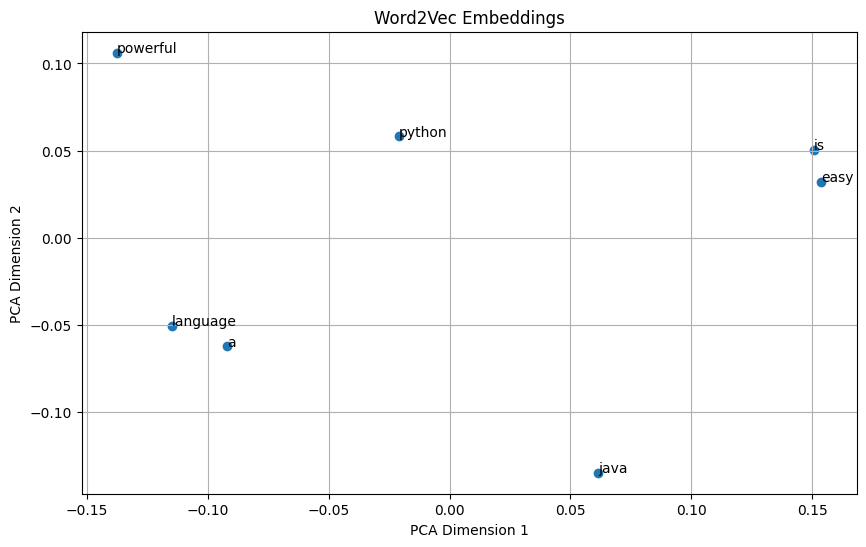

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

vocabulary = list(model.wv.key_to_index.keys())

vectors = [
    model.wv[word]
    for word in vocabulary
]

pca = PCA(n_components=2)

reduced_vectors = pca.fit_transform(vectors)

plt.figure(figsize=(10, 6))

plt.scatter(
    reduced_vectors[:, 0],
    reduced_vectors[:, 1]
)

for i, word in enumerate(vocabulary):
    plt.annotate(
        word,
        (
            reduced_vectors[i, 0],
            reduced_vectors[i, 1]
        )
    )

plt.title("Word2Vec Embeddings")
plt.xlabel("PCA Dimension 1")
plt.ylabel("PCA Dimension 2")
plt.grid(True)
plt.show()